In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
RESULT_DIR = PROJECT_ROOT / "results"

ZIP_PATH = DATA_DIR / "arcade.zip"
EXTRACT_DIR = DATA_DIR / "arcade"

print(PROJECT_ROOT)
print(DATA_DIR)

<PROJECT_ROOT>
<PROJECT_ROOT>/data


In [ ]:
import sys

!{sys.executable} -m pip install --force-reinstall opencv-python

import cv2
print(cv2.__version__)

In [2]:
# 라이브러리
from pathlib import Path
import zipfile
import os

import cv2
import numpy as np
import pandas as pd
from PIL import Image

import matplotlib.pyplot as plt

In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

ZIP_PATH = PROJECT_ROOT / "data" / "arcade.zip"
EXTRACT_DIR = PROJECT_ROOT / "data" / "arcade"

print(ZIP_PATH)
print(EXTRACT_DIR)

<PROJECT_ROOT>/data/arcade.zip
<PROJECT_ROOT>/data/arcade


In [4]:
from pathlib import Path

print(Path.cwd())
print(list(Path.cwd().iterdir()))

In [6]:
if not EXTRACT_DIR.exists():
    print("압축 해제 중...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("완료")

else:
    print("이미 압축이 풀려있습니다.")

이미 압축이 풀려있습니다.


In [5]:
# 폴더 구조 출력
def print_tree(path, max_depth=2):

    path = Path(path)

    for root, dirs, files in os.walk(path):

        level = Path(root).relative_to(path).parts

        if len(level) > max_depth:
            continue

        indent = "    " * len(level)

        print(f"{indent}{Path(root).name}/")

        for f in files[:5]:
            print(f"{indent}    {f}")

print_tree(EXTRACT_DIR)

arcade/
    arcade/
        stenosis/
        syntax/


In [6]:
# 이미지 개수

image_extensions = [
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif"
]

image_files = []

for ext in image_extensions:
    image_files.extend(EXTRACT_DIR.rglob(f"*{ext}"))

print(f"총 이미지 : {len(image_files)}")

총 이미지 : 3000


In [7]:
# 라벨개수

label_files = list(EXTRACT_DIR.rglob("*.txt"))

print(f"총 Label : {len(label_files)}")

총 Label : 0


In [8]:
from pathlib import Path

stenosis_dir = EXTRACT_DIR / "arcade" / "stenosis"

for item in sorted(stenosis_dir.iterdir()):
    print(item.name)

test
train
val


In [9]:
syntax_dir = EXTRACT_DIR / "arcade" / "syntax"

for item in sorted(syntax_dir.iterdir()):
    print(item.name)

test
train
val


In [10]:
def print_tree(path, max_depth=3):

    path = Path(path)

    for root, dirs, files in os.walk(path):

        level = len(Path(root).relative_to(path).parts)

        if level > max_depth:
            continue

        indent = "    " * level

        print(f"{indent}{Path(root).name}/")

        for f in files[:10]:
            print(f"{indent}    {f}")

print_tree(stenosis_dir)

COCO
↓
Dataset 분석
↓
YOLO Dataset 생성
↓
YOLO 학습

In [11]:
# JSON 확인
import json

train_json = (
    EXTRACT_DIR /
    "arcade" /
    "stenosis" /
    "train" /
    "annotations" /
    "train.json"
)

with open(train_json, "r") as f:
    coco = json.load(f)

print(coco.keys())

dict_keys(['images', 'annotations', 'categories'])


In [12]:
# 이미지 개수
print(len(coco["images"]))

1000


In [13]:
# annotation 개수
print(len(coco["annotations"]))

1625


In [14]:
# category 확인
coco["categories"]

[{'id': 1, 'name': '1', 'supercategory': ''},
 {'id': 2, 'name': '2', 'supercategory': ''},
 {'id': 3, 'name': '3', 'supercategory': ''},
 {'id': 4, 'name': '4', 'supercategory': ''},
 {'id': 5, 'name': '5', 'supercategory': ''},
 {'id': 6, 'name': '6', 'supercategory': ''},
 {'id': 7, 'name': '7', 'supercategory': ''},
 {'id': 8, 'name': '8', 'supercategory': ''},
 {'id': 9, 'name': '9', 'supercategory': ''},
 {'id': 10, 'name': '9a', 'supercategory': ''},
 {'id': 11, 'name': '10', 'supercategory': ''},
 {'id': 12, 'name': '10a', 'supercategory': ''},
 {'id': 13, 'name': '11', 'supercategory': ''},
 {'id': 14, 'name': '12', 'supercategory': ''},
 {'id': 15, 'name': '12a', 'supercategory': ''},
 {'id': 16, 'name': '13', 'supercategory': ''},
 {'id': 17, 'name': '14', 'supercategory': ''},
 {'id': 18, 'name': '14a', 'supercategory': ''},
 {'id': 19, 'name': '15', 'supercategory': ''},
 {'id': 20, 'name': '16', 'supercategory': ''},
 {'id': 21, 'name': '16a', 'supercategory': ''},
 {'id'

In [15]:
# 첫번재 annotation
coco["categories"]

[{'id': 1, 'name': '1', 'supercategory': ''},
 {'id': 2, 'name': '2', 'supercategory': ''},
 {'id': 3, 'name': '3', 'supercategory': ''},
 {'id': 4, 'name': '4', 'supercategory': ''},
 {'id': 5, 'name': '5', 'supercategory': ''},
 {'id': 6, 'name': '6', 'supercategory': ''},
 {'id': 7, 'name': '7', 'supercategory': ''},
 {'id': 8, 'name': '8', 'supercategory': ''},
 {'id': 9, 'name': '9', 'supercategory': ''},
 {'id': 10, 'name': '9a', 'supercategory': ''},
 {'id': 11, 'name': '10', 'supercategory': ''},
 {'id': 12, 'name': '10a', 'supercategory': ''},
 {'id': 13, 'name': '11', 'supercategory': ''},
 {'id': 14, 'name': '12', 'supercategory': ''},
 {'id': 15, 'name': '12a', 'supercategory': ''},
 {'id': 16, 'name': '13', 'supercategory': ''},
 {'id': 17, 'name': '14', 'supercategory': ''},
 {'id': 18, 'name': '14a', 'supercategory': ''},
 {'id': 19, 'name': '15', 'supercategory': ''},
 {'id': 20, 'name': '16', 'supercategory': ''},
 {'id': 21, 'name': '16a', 'supercategory': ''},
 {'id'

In [16]:
print(coco.keys())

print(len(coco["images"]))

print(len(coco["annotations"]))

print(coco["categories"])

print(coco["annotations"][0])

dict_keys(['images', 'annotations', 'categories'])
1000
1625
[{'id': 1, 'name': '1', 'supercategory': ''}, {'id': 2, 'name': '2', 'supercategory': ''}, {'id': 3, 'name': '3', 'supercategory': ''}, {'id': 4, 'name': '4', 'supercategory': ''}, {'id': 5, 'name': '5', 'supercategory': ''}, {'id': 6, 'name': '6', 'supercategory': ''}, {'id': 7, 'name': '7', 'supercategory': ''}, {'id': 8, 'name': '8', 'supercategory': ''}, {'id': 9, 'name': '9', 'supercategory': ''}, {'id': 10, 'name': '9a', 'supercategory': ''}, {'id': 11, 'name': '10', 'supercategory': ''}, {'id': 12, 'name': '10a', 'supercategory': ''}, {'id': 13, 'name': '11', 'supercategory': ''}, {'id': 14, 'name': '12', 'supercategory': ''}, {'id': 15, 'name': '12a', 'supercategory': ''}, {'id': 16, 'name': '13', 'supercategory': ''}, {'id': 17, 'name': '14', 'supercategory': ''}, {'id': 18, 'name': '14a', 'supercategory': ''}, {'id': 19, 'name': '15', 'supercategory': ''}, {'id': 20, 'name': '16', 'supercategory': ''}, {'id': 21, 'n

Train
Images : 1000장
Annotation : 1625개

즉

한 이미지당 평균 1.625개의 Annotation

In [17]:
# category 개수
from collections import Counter

counter = Counter()

for ann in coco["annotations"]:
    counter[ann["category_id"]] += 1

counter

Counter({26: 1625})

In [18]:
# 이름으로 보기
category_map = {
    c["id"] : c["name"]
    for c in coco["categories"]
}

for k, v in counter.items():
    print(category_map[k], v)

stenosis 1625


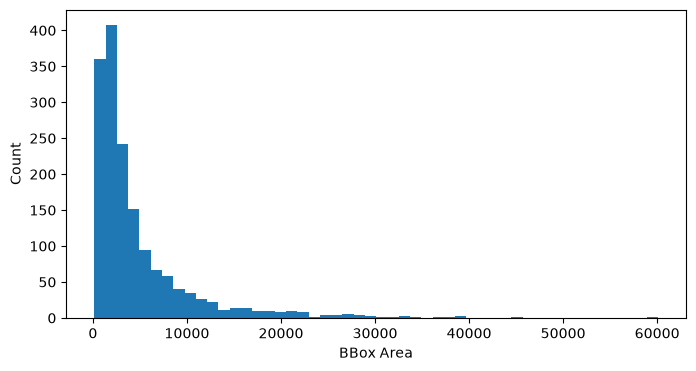

In [19]:
# bbox 크기
bbox_width = []

bbox_height = []

bbox_area = []

for ann in coco["annotations"]:

    x, y, w, h = ann["bbox"]

    bbox_width.append(w)

    bbox_height.append(h)

    bbox_area.append(w*h)

pd.Series(bbox_area).describe()

plt.figure(figsize=(8,4))

plt.hist(bbox_area, bins=50)

plt.xlabel("BBox Area")

plt.ylabel("Count")

plt.show()

학습시킬거는 stenosis 하나
1~25는 혈관 segment 정보
실제 detection 대상은 26
나중에 yolo dataset 변환할때도 class 0 = stenosis 하나만 만들면 됨

bbox 크기 보면 작은 bbox가 압도적으로 많음
병변이 20x30 또는 40x50정도밖에 안됨

In [20]:
# bbox크기 수치 확인
bbox_area = np.array(bbox_area)

print(f"Min    : {bbox_area.min():.1f}")
print(f"Max    : {bbox_area.max():.1f}")
print(f"Mean   : {bbox_area.mean():.1f}")
print(f"Median : {np.median(bbox_area):.1f}")

pd.Series(bbox_area).describe()

Min    : 152.7
Max    : 60087.2
Mean   : 4836.9
Median : 2782.6


count     1625.000000
mean      4836.932091
std       5899.819810
min        152.698200
25%       1445.989300
50%       2782.640000
75%       5589.000000
max      60087.165600
dtype: float64

# 랜덤 이미지 5장 + Bounding Box 시각화

In [21]:
# image id -> filename 만들기

image_info = {
    img["id"]: img
    for img in coco["images"]
}

In [22]:
# annotation -> image 별로 묶기

from collections import defaultdict

image_annotations = defaultdict(list)

for ann in coco["annotations"]:
    image_annotations[ann["image_id"]].append(ann)

In [23]:
# 랜덤선택

import random

sample_ids = random.sample(
    list(image_annotations.keys()),
    5
)

sample_ids

[865, 617, 826, 169, 599]

In [24]:
# 시각화 함수
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

IMAGE_DIR = (
    EXTRACT_DIR /
    "arcade" /
    "stenosis" /
    "train" /
    "images"
)

def visualize_bbox(image_id):

    image_name = image_info[image_id]["file_name"]

    image_path = IMAGE_DIR / image_name

    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(7,7))

    ax.imshow(img)

    anns = image_annotations[image_id]

    for ann in anns:

        x, y, w, h = ann["bbox"]

        rect = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=2,
            edgecolor="red",  # 빨간색이 Bounding Box
            facecolor="none"
        )

        ax.add_patch(rect)

        # polygon으로 segmetation도 보기
        
        for seg in ann["segmentation"]:

            poly = np.array(seg).reshape(-1,2)

            ax.plot(
            poly[:,0],
            poly[:,1], 
            color="lime", # 라임색 = 실제병변 mask
            linewidth=2
        )
        

    ax.set_title(f"{image_name} | {len(anns)} lesion(s)")
    ax.axis("off")

    plt.show()

for image_id in sample_ids:
    visualize_bbox(image_id)

In [25]:
print("="*50)
print("ARCADE DATASET SUMMARY")
print("="*50)

print(f"Train Images      : {len(coco['images'])}")
print(f"Annotations       : {len(coco['annotations'])}")
print(f"Classes           : {len(counter)}")
print(f"Detection Target  : stenosis")
print(f"Mean BBox Area    : {bbox_area.mean():.2f}")
print(f"Median BBox Area  : {np.median(bbox_area):.2f}")
print(f"Max BBox Area     : {bbox_area.max():.2f}")
print(f"Min BBox Area     : {bbox_area.min():.2f}")

ARCADE DATASET SUMMARY
Train Images      : 1000
Annotations       : 1625
Classes           : 1
Detection Target  : stenosis
Mean BBox Area    : 4836.93
Median BBox Area  : 2782.64
Max BBox Area     : 60087.17
Min BBox Area     : 152.70


생각보다 segmentation 품질이 좋음

Polygon이 혈관 중심을 꽤 정확하게 따라감
Bounding Box도 병변 영역을 크게 벗어나지 않음
Label 품질이 일정함